# 실습 시작 전 세팅

In [ ]:
# 드라이브 마운트 하기

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# 필요한 라이브러리 설치 및 데이터 준비하기

### 데이터 준비

***GDC-client로 TCGA slide image 다운 받기***

In [ ]:
# 현재 폴더에 압축 풀기

!unzip "/content/drive/MyDrive/gdc-client_v1.6.1_Ubuntu_x64.zip"

Archive:  /content/drive/MyDrive/4. ML DL archive/0. 생명정보학 및 신약 개발 개념 노트/LAIDD 신약 개발 강의 노트/초급 강의 노트/생물정보학/10. 의료이미지 기반 환자진단 및 바이오마커 탐색/gdc-client_v1.6.1_Ubuntu_x64.zip
 extracting: gdc-client              


In [ ]:
# 1. gdc-client 파일에 실행 권한 부여
!chmod +x ./gdc-client

# 2. 매니페스트 파일을 참조하여 현재 폴더에 WSI 다운로드 (경로 수정 및 따옴표 추가)
!./gdc-client download -m "/content/drive/MyDrive/gdc_manifest_20220410_013342.txt"

100% [#############################################] Time:  0:00:34   3.3 MiB/s 
Successfully downloaded: 1


### 필요한 라이브러리 준비

In [ ]:
# Install ttach(Image Test Time Augmentation with PyTorch)
!pip install ttach

# Install python-openslide
!apt update && apt install -y openslide-tools
!pip install openslide-python

Hit:1 https://cli.github.com/packages stable InRelease
Get:2 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ InRelease [3,632 B]
Get:3 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  InRelease [1,578 B]
Get:4 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  Packages [2,915 kB]
Get:5 http://security.ubuntu.com/ubuntu jammy-security InRelease [129 kB]
Hit:6 http://archive.ubuntu.com/ubuntu jammy InRelease
Get:7 http://archive.ubuntu.com/ubuntu jammy-updates InRelease [128 kB]
Hit:8 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu jammy InRelease
Hit:9 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu jammy InRelease
Get:10 https://r2u.stat.illinois.edu/ubuntu jammy InRelease [6,555 B]
Hit:11 https://ppa.launchpadcontent.net/ubuntugis/ppa/ubuntu jammy InRelease
Get:12 https://r2u.stat.illinois.edu/ubuntu jammy/main amd64 Packages [3,180 kB]
Get:13 http://security.ubuntu.com/ubuntu jammy-security/restricted 

# 데이터 전처리 (data pre-processing)

### openslide 이용하여 WSI 다루기

In [ ]:
from PIL import Image
import openslide
import numpy as np


In [ ]:
# openslide로 whole slide image(WSI) 불러오기
# TCGA-COAD
slide_mask = openslide.open_slide("/content/ed500fa9-70b1-4d52-9e73-d8d512448901/TCGA-AD-6901-01Z-00-DX1.0a69c0b5-6238-4c1a-bbbd-ea743bf6fc98.svs")


top_left = (6000, 6000) # top left 픽셀 값
level_dim = slide_mask.level_dimensions # WSI levels
for i, dim in enumerate(level_dim):
    print(f"Level{i} 픽셀 크기: {dim}")

vis_level = 0 # WSI level (0 - 가장 큰 magnification)
region_size = level_dim[vis_level] # 해당 level에서 전체 픽셀 크기


Level0 픽셀 크기: (35492, 32395)
Level1 픽셀 크기: (8873, 8098)
Level2 픽셀 크기: (2218, 2024)


***Magnification 바꾸기***

In [ ]:
# 자를 이미지 크기

crop_size = (224 * 4, 224 * 4)

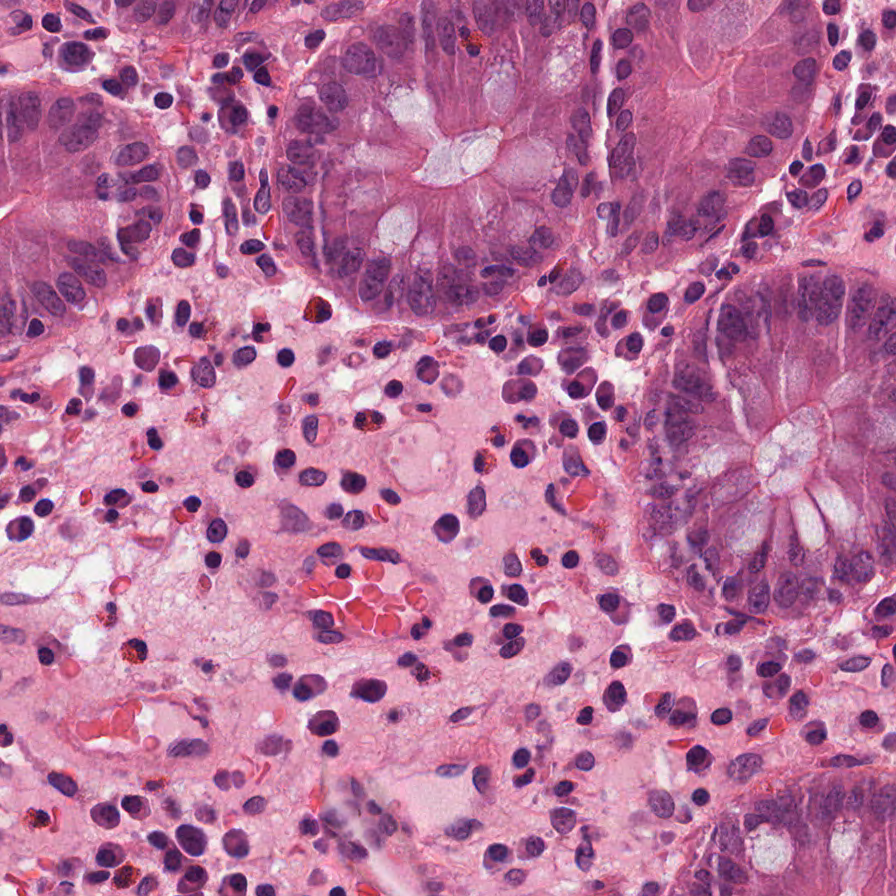

In [ ]:
# vis_level 0 (20x magnification)

slide_mask.read_region(top_left, 0, crop_size).convert("RGB")

In [ ]:
# vis_level 1 (10x magnification)

slide_mask.read_region(top_left, 1, crop_size)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# vis_level 2 (5x magnification)

slide_mask.read_region(top_left, 2, crop_size)

Output hidden; open in https://colab.research.google.com to view.

### 테스트 진행을 위한 전처리

In [ ]:
# WSI 자르기

top_left = (5000, 5000)
crop_size = (224 * 18, 224 * 18)

In [ ]:
# WSI 이미지 잘라서 가져오기

test_im2arr = np.array(slide_mask.read_region(top_left, 0, crop_size).convert("RGB"))

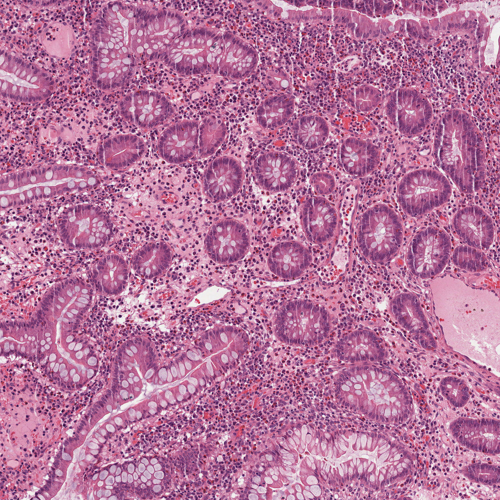

In [ ]:
Image.fromarray(test_im2arr).resize((500,500))

### Whole slide image (WSI) 패치 이미지로 나누기

In [ ]:

slide_x_size = test_im2arr.shape[1] # WSI의 열 차원 크기
slide_y_size = test_im2arr.shape[0] # WSI의 행 차원 크기

# 추출할 패치 사이즈
step_x = 224 # X축(열방향) 사이즈
step_y = 224 # Y축(행방향) 사이즈

# 각 축 별 추출할 패치 개수
num_x = int(slide_x_size/step_x) # X축 방향 개수
num_y = int(slide_y_size/step_y) # Y축 방향 개수
print(f"총 패치 데이터의 개수: {num_x*num_y}")

# WSI를 패치로 나누어 리스트에 저장
image_split_list = []

for y_index in range(0, num_y):
    for x_index in range(0, num_x):
        temp_image = test_im2arr[step_y * y_index : step_y * (y_index + 1), step_x * x_index : step_x * (x_index + 1)]
        image_split_list.append(temp_image)


총 패치 데이터의 개수: 324


array([[[182,  97, 138],
        [159,  74, 115],
        [126,  57, 101],
        ...,
        [156,  79, 147],
        [116,  55, 122],
        [105,  44, 111]],

       [[209, 110, 141],
        [199, 100, 131],
        [175,  93, 129],
        ...,
        [159,  85, 144],
        [125,  65, 127],
        [109,  49, 111]],

       [[229, 123, 145],
        [232, 126, 148],
        [218, 128, 156],
        ...,
        [162,  93, 138],
        [131,  76, 133],
        [113,  58, 115]],

       ...,

       [[203, 137, 165],
        [216, 150, 178],
        [230, 156, 189],
        ...,
        [181, 124, 167],
        [186, 124, 171],
        [183, 121, 168]],

       [[207, 144, 175],
        [218, 155, 186],
        [232, 162, 198],
        ...,
        [170, 117, 161],
        [184, 118, 164],
        [183, 117, 163]],

       [[206, 145, 179],
        [217, 156, 190],
        [229, 165, 202],
        ...,
        [166, 108, 158],
        [178, 109, 154],
        [180, 111, 156]]], dtype=uint8)
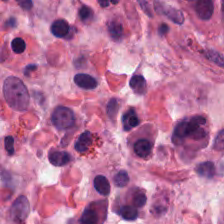

In [ ]:
image_split_list[0]

### 테스트 세팅

In [ ]:
# 필요한 라이브러리 불러오기
from tqdm import tqdm

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, models, transforms
from torchvision.models import resnet50
import torch.nn as nn

In [ ]:
# 디바이스 설정

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"현재 디바이스는 {device} 입니다.")

현재 디바이스는 cuda:0 입니다.


In [ ]:
# data transform 적용하기

image_transforms = {
    'train': transforms.Compose([
        # transforms.Resize(size=224),
        transforms.ToTensor(),

        # data augmentation
        transforms.RandomRotation(90, expand=False),
        transforms.RandomRotation(180, expand=False),
        transforms.RandomRotation(270, expand=False),

        transforms.Normalize([0.485, 0.456, 0.406],
                             [0.229, 0.224, 0.225])
    ]),
    'valid': transforms.Compose([
        # transforms.Resize(size=224),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406],
                             [0.229, 0.224, 0.225])
    ])
}


In [ ]:
# Dataset 클래스 직접 정의하기

class Image_Array_list_test_Dataset(Dataset):
    """
    슬라이드 패치 이미지를 위한 추상클래스

    torch.utils.data.Dataset 를 상속 받아 오버라이드
    """

    def __init__(self, data, transform=None):
        """
        Args:
            data: 추출한 패치들이 담긴 리스트
            transform: 데이터에 적용될 transform (optinal)
        """
        self.data = data
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        x = self.data[index]

        if self.transform:
            x = Image.fromarray(self.data[index].astype(np.uint8))
            x = self.transform(x)

        return x


In [ ]:
# 패치 데이터 데이터셋 인스턴스 생성
test_Dataset = Image_Array_list_test_Dataset(image_split_list, transform=image_transforms['valid'])

# 데이터로더 적용
test_dataloader = DataLoader(test_Dataset, batch_size=32)

In [ ]:
# 데이터 확인해보기
print(f"이미지 shape = {list(test_Dataset[0].shape)}")

이미지 shape = [3, 224, 224]


In [ ]:
print(f"이미지 크기 = {len(test_Dataset)}")

이미지 크기 = 324


In [ ]:
# 데이터 레이블
Classes = ['ADI', 'BAC', 'LYM', 'MUC', 'MUS', 'NOR', 'STR', 'TUM']

num_classes = len(Classes)

![](https://drive.google.com/uc?export=view&id=14m2NqQd7s7pnEF_T3lMF17G4MzN10Vr6)



### 미리 학습한 모델 가져오기

In [ ]:
# resnet50 모델 불러오기
model = resnet50(pretrained=False)

# 마지막 layer 변경 (2048 -> 1000 => 2048 -> 128 -> num_classes)
model.fc = nn.Sequential(
               nn.Linear(2048, 128),
               nn.ReLU(inplace=True),
               nn.Linear(128, num_classes))

# model device에 올리기
model = model.to(device)

# 미리 학습
model.load_state_dict(torch.load("/content/drive/MyDrive/model.pt"))

<All keys matched successfully>

In [ ]:
model

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

***이미지 오버레이(overlay) 세팅***

In [ ]:
import numpy as np
# 데이터 레이블
Classes = ['ADI', 'BAC', 'LYM', 'MUC', 'MUS', 'NOR', 'STR', 'TUM']

num_classes = len(Classes)

In [ ]:
def plot_pixel_color(mask_color):
    """픽셀 색 보여주기
    """

    # from skimage import io
    import matplotlib.pyplot as plt

    num = mask_color.shape[0]

    ind = np.arange(num).reshape(1,num)

    fig = plt.figure(figsize=(num,2))
    ax = fig.add_subplot(111)
    ax.imshow(mask_color[ind])
    ax.set_yticks([])
    ax.set_xticks(range(num))
    ax.set_xticklabels(Classes)

    plt.show()

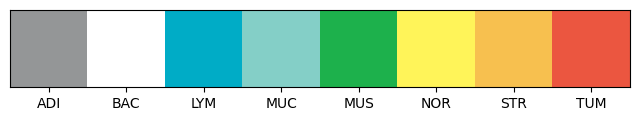

In [ ]:
# 각 클래스 별로 masking할 색 정하기

image_mask_color =  np.array([
    [148, 150, 151],  # ADI
    [255, 255, 255],  # BAC
    # [187, 128, 183],
    [0,   172, 198],  # LYM
    [132, 207, 199], # MUC
    [29,  177,  76], # MUS
    [255, 244,  89], # NOR
    [247, 192,  79], # STR
    [235,  86,  64]   # TUM
])

image_mask_color = image_mask_color / 255


plot_pixel_color(image_mask_color)

In [ ]:
def apply_mask_image(image, color, alpha=0.5):
    """픽셀별로 mask 적용하기

    Args:
        image: 각 픽셀 값
        color: 클래스 별 masking color 값을 행으로 하는 행렬 (8x3)
        alpha: 투명도 [0,1]

    Returns:
        image에 mask 입힌 이미지 반환
    """

    new_image = (1 - alpha) * image + alpha * image_mask_color[color] * 255

    return new_image


In [ ]:
def image_crop_list_to_total_image(image_array_list, step_y, step_x, step_num_y, step_num_x):
    """masking한 패치 이미지를 다시 전체 슬라이드 이미지로 합치기

    Args:
        image_array_list:
        step_y: 패치 이미지 Y축 사이즈
        step_x: 패치 이미지 X축 사이즈
        step_num_y: Y축 방향 패치 이미지 개수
        step_num_x: X축 방향 패치 이미지 개수

    Returns:
        합쳐진 전체 슬라이드 이미지
    """

    if len(image_array_list) != step_num_y * step_num_x:
        raise Exception('length of image_Array_list is not same to step_num_y X step_num_X')

    # 전체 슬라이드 이미지와 같은 크기의 영행렬 생성
    out_image_array = np.zeros((step_y * step_num_y, step_x * step_num_x, 3), dtype = np.uint8)

    # masking 된 패치 이미지로 이루어진 전체 슬라이드 이미지 생성
    cnt = 0
    for y_index in range(0, step_num_y):
        for x_index in range(0, step_num_x):
            out_image_array[step_y * y_index : step_y * (y_index + 1), step_x * x_index : step_x * (x_index + 1)] = image_array_list[cnt]
            cnt += 1

    return out_image_array


### 패치 별 segmentation

In [ ]:
label_list = []

# 학습한 모델을 이용해 inference
for inputs in tqdm(test_dataloader):

    inputs = inputs.to(device, non_blocking=True) # [batch_size, 3, 224, 224]
    outputs = model(inputs) # [batch_size x num_classes(8)]
    outputs = outputs.cpu().detach().numpy()
    label_list.extend(np.argmax(outputs, 1).tolist()) # inference한 클래스 리스트에 담기

# 패치 별 mask 오버레이(overlay)
out_result_image_list = []
for index, seg_label_image in enumerate(tqdm(label_list)):
    new_image = apply_mask_image(image_split_list[index], label_list[index])
    out_result_image_list.append(new_image)


100%|██████████| 324/324 [00:00<00:00, 823.45it/s]


In [ ]:
# 패치 이미지 하나로 병합
merge_image = image_crop_list_to_total_image(out_result_image_list, step_x, step_y, num_y, num_x)
test_merge_image = Image.fromarray(merge_image)

# 시각화를 위해 사이즈 줄이기
test_merge_image = test_merge_image.resize((int(test_merge_image.width / 6), int(test_merge_image.height / 6)))

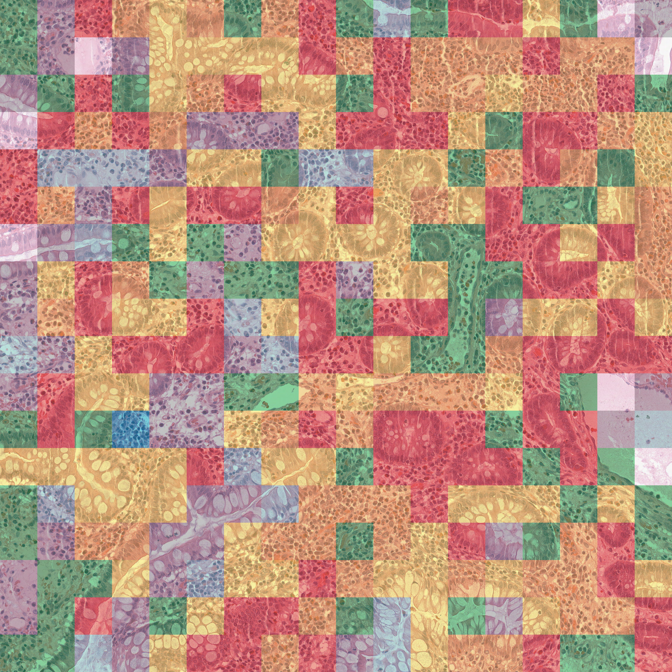

In [ ]:
test_merge_image

# 수고하셨습니다.